# 07 · Phase 4: synthetic validation of the registered confirmatory pipeline

**No combine measurement is joined to any NFL game outcome here.** Every synthetic dataset uses a *real design*: actual eligible players, plays per context, team-seasons, routes, coverages, downs, seasons and experience. Its outcome and combine predictors are synthetic.

Nuisance parameters come from outcome-only REML fits.

How to reproduce:
1. Run `python scripts/run_synthetic_validation.py skeleton`.
2. Run each stage, `h1 h1_db h2 selection family selection_real demand_real demand_reliability demand_sim h1_s8fix h1_warp h1_direct h1_warp_db family_reml`, with a common run id. Then run `python scripts/db_correlation_decomposition.py`.
3. Run `python scripts/build_notebook_07.py`, then execute this notebook.

Seeds come from `SeedSequence([4004, scenario, replicate])`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, polars as pl, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'scripts')]
from nfl_bdb.visualization import style
from nfl_bdb.models.validation_summary import summarise_h1, summarise_h2
import phase4_stages as ps
style.apply()
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(30); pl.Config.set_tbl_width_chars(220); pl.Config.set_float_precision(3)
RUN = (ROOT / 'experiments/synthetic_validation/LATEST').read_text().strip()
OUT = ROOT / 'experiments/synthetic_validation' / RUN
FIG = ROOT / 'reports/figures'
cal = json.load(open(ROOT / 'data/interim/phase4/calibration.json'))
print('run', RUN); print(json.dumps({k: {kk: vv for kk, vv in v.items() if kk in ('n_eligible','n_players','n_team','s2_team','sigma_b','s2b','corr_b','team_share_of_between','reliability_mean')} for k, v in cal.items()}, indent=1))

run 20261121T023847Z
{
 "WR": {
  "sigma_b": [
   [
    0.061605059747813974,
    0.05571839897317614
   ],
   [
    0.05571839897317614,
    0.08485169435562927
   ]
  ],
  "s2_team": 0.010396694804759425,
  "n_eligible": 57,
  "n_team": 76,
  "team_share_of_between": 0.12432509263014366,
  "corr_b": 0.7706553146779512
 },
 "DB": {
  "sigma_b": [
   [
    0.04190147977454409,
    0.01386186691241438
   ],
   [
    0.01386186691241438,
    0.034598170746760935
   ]
  ],
  "s2_team": 0.005341143698464732,
  "n_eligible": 52,
  "n_team": 74,
  "team_share_of_between": 0.12252867568679288,
  "corr_b": 0.36406629637138677
 },
 "H2": {
  "s2b": 0.01586609857953785,
  "s2_team": 0.01749150926791149,
  "n_players": 57,
  "n_team": 70,
  "reliability_mean": 0.43250129551313515
 }
}


## 1. H1: registered procedure across the six required scenario families

In [2]:
h1 = pl.read_parquet(OUT / 'h1_WR.parquet')
fix = OUT / 'h1_WR_s8fix.parquet'
if fix.exists():
    h1 = pl.concat([h1.filter(pl.col('scenario') != 8), pl.read_parquet(fix)], how='diagonal_relaxed')
S1 = summarise_h1(h1)
S1.select('scenario','label','reps','true_delta_obs','reject','reject_mcse','reject_holm','reject_raw_contrast',
          'mean_delta_reml','bias_reml','bias_reml_mcse','bias_moment','coverage95','coverage_mcse','sd_delta_reml','mean_se_boot','disagree_rate')

scenario,label,reps,true_delta_obs,reject,reject_mcse,reject_holm,reject_raw_contrast,mean_delta_reml,bias_reml,bias_reml_mcse,bias_moment,coverage95,coverage_mcse,sd_delta_reml,mean_se_boot,disagree_rate
i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""S1 null (rho 0.3 / 0.3)""",400,0.000,0.045,0.010,0.018,0.052,0.005,0.005,0.006,0.010,0.927,0.013,0.112,0.111,0.198
2,"""S1b null, no association (0 / …",400,0.000,0.043,0.010,0.015,0.043,0.002,0.002,0.006,0.016,0.943,0.012,0.114,0.114,0.242
3,"""S2 small (0.4 / 0.3)""",400,0.099,0.140,0.017,0.085,0.175,0.091,-0.009,0.006,-0.006,0.920,0.014,0.111,0.109,0.203
4,"""S3 moderate (0.5 / 0.3)""",400,0.199,0.468,0.025,0.310,0.507,0.198,-0.000,0.006,-0.009,0.932,0.013,0.113,0.104,0.278
5,"""S4 large (0.65 / 0.3)""",400,0.348,0.897,0.015,0.820,0.930,0.343,-0.005,0.005,-0.020,0.915,0.014,0.107,0.105,0.287
6,"""S5a deployment only: route mix…",400,0.000,0.005,0.004,0.000,0.007,-0.003,-0.003,0.005,-0.058,0.938,0.012,0.104,0.113,0.492
7,"""S5b selection on outcome: play…",400,0.000,0.045,0.010,0.010,0.058,0.019,0.019,0.006,0.023,0.932,0.013,0.119,0.119,0.177
9,"""S6b combine measurement error …",400,0.179,0.367,0.024,0.220,0.407,0.175,-0.003,0.005,-0.012,0.940,0.012,0.104,0.108,0.242
10,"""S1 null with empirical (non-no…",400,0.000,0.043,0.010,0.025,0.048,0.004,0.004,0.006,0.011,0.920,0.014,0.115,0.108,0.170


In [3]:
warp_path = OUT / 'h1_warp.parquet'
if warp_path.exists():
    W = pl.read_parquet(warp_path)
    if (OUT / 'h1_warp_extra.parquet').exists():
        W = pl.concat([W, pl.read_parquet(OUT / 'h1_warp_extra.parquet')], how='diagonal_relaxed')
    WR = pl.concat([ps.warp_decisions(W, 'delta_reml', 'reml_boot'), ps.warp_decisions(W, 'delta_moment', 'moment_boot')])
    exact = W.group_by('scenario').agg(pl.col('supported_full_moment').mean().alias('exact_full_B_moment_reject')).sort('scenario')
    display(WR.sort('scenario','estimator').join(exact, on='scenario'))

scenario,label,estimator,reps,pooled_draws,reject,reject_mcse,coverage95,boot_sd,sd_estimate,bias,exact_full_B_moment_reject
i64,str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64
1,"""S1 null (rho 0.3 / 0.3)""","""delta_moment""",400,4000,0.025,0.008,0.963,0.113,0.115,0.010,0.045
1,"""S1 null (rho 0.3 / 0.3)""","""delta_reml""",400,4000,0.007,0.004,0.993,0.159,0.112,0.005,0.045
2,"""S1b null, no association (0 / …","""delta_moment""",400,4000,0.033,0.009,0.960,0.117,0.119,0.016,0.043
2,"""S1b null, no association (0 / …","""delta_reml""",400,4000,0.000,0.000,1.000,0.173,0.114,0.002,0.043
3,"""S2 small (0.4 / 0.3)""","""delta_moment""",400,4000,0.122,0.016,0.938,0.109,0.113,-0.006,0.140
3,"""S2 small (0.4 / 0.3)""","""delta_reml""",400,4000,0.072,0.013,0.993,0.159,0.111,-0.009,0.140
4,"""S3 moderate (0.5 / 0.3)""","""delta_moment""",400,4000,0.430,0.025,0.958,0.106,0.112,-0.009,0.468
4,"""S3 moderate (0.5 / 0.3)""","""delta_reml""",400,4000,0.448,0.025,0.958,0.147,0.113,-0.000,0.468
5,"""S4 large (0.65 / 0.3)""","""delta_moment""",400,4000,0.863,0.017,0.953,0.107,0.109,-0.020,0.897


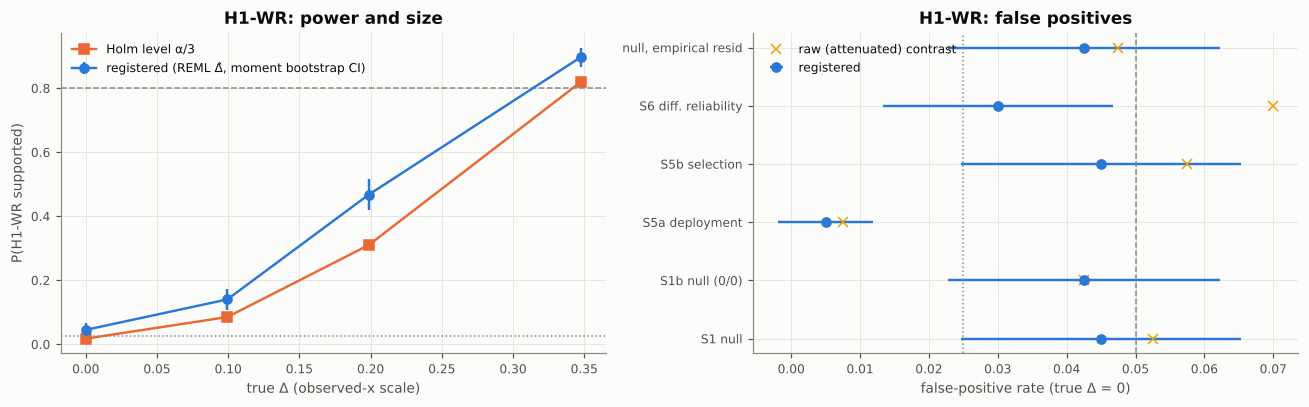

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
pw = S1.filter(pl.col('scenario').is_in([1, 3, 4, 5])).sort('true_delta_obs')
ax[0].errorbar(pw['true_delta_obs'], pw['reject'], yerr=1.96*pw['reject_mcse'], marker='o', color=style.SERIES[0], label='registered (REML Δ̂, moment bootstrap CI)')
ax[0].plot(pw['true_delta_obs'], pw['reject_holm'], marker='s', color=style.SERIES[1], label='Holm level α/3')
ax[0].axhline(0.8, color=style.MUTED, ls='--', lw=1); ax[0].axhline(0.025, color=style.MUTED, ls=':', lw=1)
ax[0].set_xlabel('true Δ (observed-x scale)'); ax[0].set_ylabel('P(H1-WR supported)'); ax[0].legend(); ax[0].set_title('H1-WR: power and size')
lab = {1:'S1 null', 2:'S1b null (0/0)', 6:'S5a deployment', 7:'S5b selection', 8:'S6 diff. reliability', 10:'null, empirical resid'}
nul = S1.filter(pl.col('scenario').is_in(list(lab))).sort('scenario')
ypos = np.arange(nul.height)
ax[1].errorbar(nul['reject'], ypos, xerr=1.96*nul['reject_mcse'], fmt='o', color=style.SERIES[0], label='registered')
ax[1].plot(nul['reject_raw_contrast'], ypos, 'x', color=style.SERIES[3], label='raw (attenuated) contrast')
ax[1].axvline(0.025, color=style.MUTED, ls=':', lw=1); ax[1].axvline(0.05, color=style.MUTED, ls='--', lw=1)
ax[1].set_yticks(ypos, [lab[s] for s in nul['scenario']]); ax[1].set_xlabel('false-positive rate (true Δ = 0)'); ax[1].legend(); ax[1].set_title('H1-WR: false positives')
fig.tight_layout(); fig.savefig(FIG / 'p4_h1_power_size.png', dpi=150); plt.show()

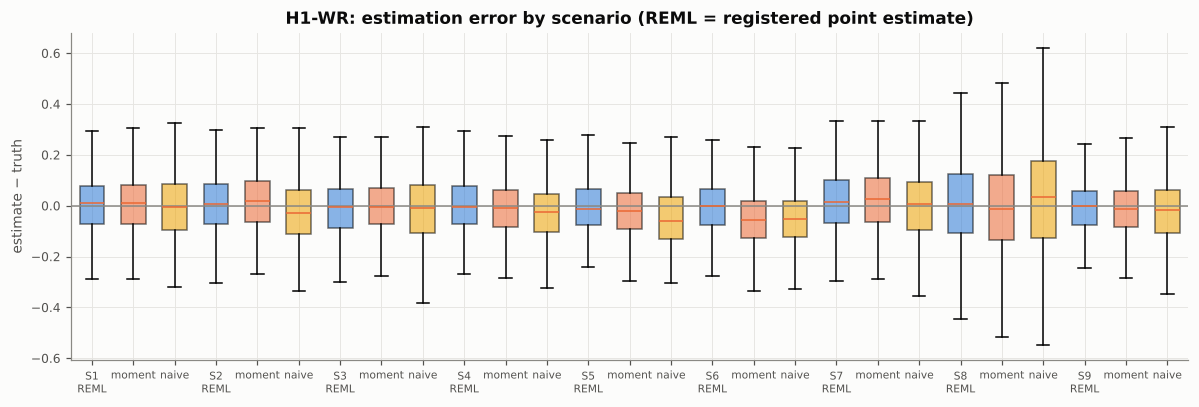

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.8))
order = [1, 2, 3, 4, 5, 6, 7, 8, 9]
data, labels, cols = [], [], []
for s in order:
    g = h1.filter(pl.col('scenario') == s); tr = g['true_delta_obs'][0]
    data += [g['delta_reml'].to_numpy() - tr, g['delta_moment'].to_numpy() - tr, g['delta_naive_unadj'].to_numpy() - tr]
    labels += [f'S{s}\nREML', 'moment', 'naive']; cols += [style.SERIES[0], style.SERIES[1], style.SERIES[3]]
bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False)
for p, c in zip(bp['boxes'], cols): p.set_facecolor(c); p.set_alpha(0.55)
ax.axhline(0, color=style.MUTED, lw=1); ax.set_xticks(range(1, len(labels)+1), labels, fontsize=7); ax.set_ylabel('estimate − truth')
ax.set_title('H1-WR: estimation error by scenario (REML = registered point estimate)')
fig.tight_layout(); fig.savefig(FIG / 'p4_h1_bias.png', dpi=150); plt.show()

In [6]:
direct = OUT / 'h1_direct.parquet'
if direct.exists():
    D = pl.read_parquet(direct)
    W = pl.read_parquet(OUT / 'h1_warp.parquet').select('scenario','rep', pl.col('delta_reml').alias('d_warp'), 'reml_boot')
    J = D.join(W, on=['scenario','rep'])
    rows = []
    for (s,), g in J.group_by('scenario', maintain_order=True):
        allw = W.filter(pl.col('scenario') == s)
        cen = np.concatenate([np.asarray(b) - e for b, e in zip(allw['reml_boot'].to_list(), allw['d_warp'].to_list())])
        qlo = np.percentile(cen, 2.5)
        warp_lo = g['delta_reml'].to_numpy() + qlo
        rows.append(dict(scenario=s, reps=g.height, same_point_estimate=bool(np.allclose(g['delta_reml'], g['d_warp'])),
                         direct_reject=float(((g['ci_lo'] > 0) & (g['delta_reml'] > 0)).mean()),
                         direct_coverage=float(((g['ci_lo'] <= g['true_delta_obs']) & (g['ci_hi'] >= g['true_delta_obs'])).mean()),
                         mean_direct_se=float(g['se'].mean()), pooled_warp_sd=float(cen.std()),
                         corr_lower_bounds=float(np.corrcoef(g['ci_lo'], warp_lo)[0, 1]),
                         mean_lower_bound_diff=float((g['ci_lo'] - warp_lo).mean())))
    display(pl.DataFrame(rows))

scenario,reps,same_point_estimate,direct_reject,direct_coverage,mean_direct_se,pooled_warp_sd,corr_lower_bounds,mean_lower_bound_diff
i64,i64,bool,f64,f64,f64,f64,f64,f64
1,60,true,0.000,0.983,0.156,0.159,0.853,0.015
6,40,true,0.000,0.975,0.160,0.171,0.678,0.021


**Why the full REML bootstrap is conservative (mechanism).** A resampled player drawn twice contributes two identical copies of his plays on the same team-season. REML attributes their perfect agreement partly to the team-season effect: s2_team inflates and Σ_b shrinks, so ρ_c = β_c / √(β_c² + Σ_b,cc) becomes more variable across resamples. Three replicates of S1, 40 resamples each (about 1 minute):

In [7]:
ps.bootstrap_mechanism_diagnostic(reps=3, B=40)

rep,delta,s2_team,sb_hh,sb_ll,boot_mean_s2_team,boot_mean_sb_hh,boot_mean_sb_ll,boot_sd_delta,sampling_sd_delta_S1
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,-0.137,0.014,0.049,0.051,0.043,0.017,0.027,0.225,0.112
1,-0.139,0.014,0.072,0.099,0.025,0.050,0.074,0.118,0.112
2,0.205,0.008,0.038,0.078,0.015,0.025,0.061,0.149,0.112


In [8]:
db = summarise_h1(pl.read_parquet(OUT / 'h1_DB.parquet'))
db.select('scenario','label','reps','reject','reject_mcse','bias_reml','coverage95','sd_delta_reml','mean_se_boot')

scenario,label,reps,reject,reject_mcse,bias_reml,coverage95,sd_delta_reml,mean_se_boot
i64,str,i64,f64,f64,f64,f64,f64,f64
1,"""S1 null (rho 0.3 / 0.3)""",200,0.225,0.030,0.009,0.740,0.211,0.228
4,"""S3 moderate (0.5 / 0.3)""",200,0.560,0.035,0.007,0.760,0.205,0.219


**H1-DB under the full REML bootstrap (warp-speed).** The registered fallback (moment bootstrap with pooled residualisation) is misspecified for DB, as the decomposition below shows.

In [9]:
wdb = OUT / 'h1_warp_DB.parquet'
if wdb.exists():
    WD = pl.read_parquet(wdb)
    display(pl.concat([ps.warp_decisions(WD, 'delta_reml', 'reml_boot'), ps.warp_decisions(WD, 'delta_moment', 'moment_boot')]).sort('scenario', 'estimator'))

scenario,label,estimator,reps,pooled_draws,reject,reject_mcse,coverage95,boot_sd,sd_estimate,bias
i64,str,str,i64,i64,f64,f64,f64,f64,f64,f64
1,"""S1 null (rho 0.3 / 0.3)""","""delta_moment""",200,2000,0.280,0.032,0.720,0.230,0.230,0.285
1,"""S1 null (rho 0.3 / 0.3)""","""delta_reml""",200,2000,0.000,0.000,1.000,0.366,0.211,0.009
4,"""S3 moderate (0.5 / 0.3)""","""delta_moment""",200,2000,0.580,0.035,0.795,0.221,0.228,0.247
4,"""S3 moderate (0.5 / 0.3)""","""delta_reml""",200,2000,0.025,0.011,1.000,0.307,0.205,0.007


### DB: why the man / underneath-zone player correlation changed sign (outcome-only, real data)

In [10]:
pl.Config.set_fmt_str_lengths(70)
pl.read_parquet(OUT / 'db_corr_decomposition.parquet').filter(pl.col('data').str.starts_with('registered'))

data,spec,corr,n
str,str,f64,i64
"""registered (nullified plays excluded)""","""A. pooled residualisation (3 contexts), moment""",-0.326,52
"""registered (nullified plays excluded)""","""B. as A without lined_up_position""",-0.331,52
"""registered (nullified plays excluded)""","""C. pooled residualisation, 2 contexts, moment""",-0.250,52
"""registered (nullified plays excluded)""","""D. context-specific residualisation, moment""",0.357,52
"""registered (nullified plays excluded)""","""E. REML, context-specific covariates, no team-season""",0.426,52
"""registered (nullified plays excluded)""","""F. REML + team-season random effect (registered)""",0.361,52
"""registered (nullified plays excluded)""","""G. REML with COMMON covariate effects + team-season""",-0.230,52


## 2. H2: incremental value of tracked peak speed beyond the official 40

In [11]:
h2 = pl.read_parquet(OUT / 'h2.parquet'); S2 = summarise_h2(h2)
S2.select('scenario','label','reps','true_partial','reject','reject_mcse','reject_holm','reject_wald_reml','full_support','mean_partial_hat','bias_partial','sd_partial_hat',
          'agree_sign_reml_2s','mean_dr2_cv','p_dr2_ge_002','p_lb90_pos','p_eiv_pos','mean_dRMSE_sf')

scenario,label,reps,true_partial,reject,reject_mcse,reject_holm,reject_wald_reml,full_support,mean_partial_hat,bias_partial,sd_partial_hat,agree_sign_reml_2s,mean_dr2_cv,p_dr2_ge_002,p_lb90_pos,p_eiv_pos,mean_dRMSE_sf
i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""partial 0.0""",400,0.000,0.028,0.008,0.010,0.028,0.000,0.015,0.015,0.316,0.887,-0.022,0.062,0.000,0.492,0.001
2,"""partial 0.1""",400,0.100,0.065,0.012,0.028,0.070,0.005,0.094,-0.006,0.276,0.925,-0.022,0.083,0.005,0.620,0.001
3,"""partial 0.2""",400,0.200,0.140,0.017,0.050,0.138,0.003,0.209,0.009,0.287,0.943,-0.012,0.163,0.007,0.740,0.000
4,"""partial 0.3""",400,0.300,0.290,0.023,0.150,0.302,0.015,0.342,0.042,0.286,0.955,0.008,0.333,0.028,0.860,-0.000
5,"""partial 0.4""",400,0.400,0.365,0.024,0.198,0.400,0.035,0.403,0.003,0.267,0.978,0.017,0.410,0.050,0.907,-0.000
6,"""partial 0, R_F 0.90""",300,0.000,0.040,0.011,0.013,0.027,0.000,0.039,0.039,0.302,0.943,-0.019,0.077,0.000,0.503,0.001
7,"""partial 0, R_F 0.99""",300,0.000,0.027,0.009,0.013,0.043,0.000,0.020,0.020,0.311,0.957,-0.022,0.070,0.003,0.497,0.001
8,"""partial 0, R_x 0.90""",300,0.000,0.037,0.011,0.027,0.047,0.003,0.030,0.030,0.321,0.917,-0.018,0.090,0.010,0.507,0.001
9,"""partial 0.3, R_F 0.90""",300,0.300,0.233,0.024,0.133,0.253,0.017,0.342,0.042,0.307,0.963,0.003,0.257,0.027,0.860,0.000


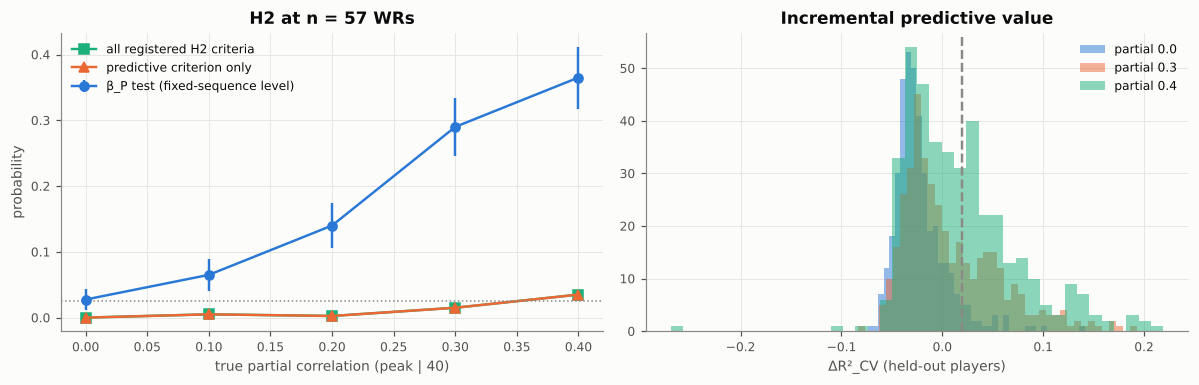

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
m = S2.filter(pl.col('scenario') <= 5).sort('true_partial')
ax[0].errorbar(m['true_partial'], m['reject'], yerr=1.96*m['reject_mcse'], marker='o', color=style.SERIES[0], label='β_P test (fixed-sequence level)')
ax[0].plot(m['true_partial'], m['full_support'], marker='s', color=style.SERIES[2], label='all registered H2 criteria')
ax[0].plot(m['true_partial'], m['p_predictive_ok'], marker='^', color=style.SERIES[1], label='predictive criterion only')
ax[0].axhline(0.025, color=style.MUTED, ls=':', lw=1); ax[0].set_xlabel('true partial correlation (peak | 40)'); ax[0].set_ylabel('probability'); ax[0].legend(); ax[0].set_title('H2 at n = 57 WRs')
for k, s in enumerate([1, 4, 5]):
    g = h2.filter(pl.col('scenario') == s)
    ax[1].hist(g['dr2_cv'], bins=40, alpha=0.5, color=style.SERIES[k], label=f'partial {g["true_partial"][0]}')
ax[1].axvline(0.02, color=style.MUTED, ls='--'); ax[1].set_xlabel('ΔR²_CV (held-out players)'); ax[1].legend(); ax[1].set_title('Incremental predictive value')
fig.tight_layout(); fig.savefig(FIG / 'p4_h2.png', dpi=150); plt.show()

In [13]:
S2.select('scenario','label','mean_dr2_player_cv_same_reps','mean_dr2_playsplit')

scenario,label,mean_dr2_player_cv_same_reps,mean_dr2_playsplit
i64,str,f64,f64
1,"""partial 0.0""",-0.024,-0.001
2,"""partial 0.1""",-0.020,-0.000
3,"""partial 0.2""",-0.013,0.002
4,"""partial 0.3""",0.001,0.003
5,"""partial 0.4""",0.017,0.006
6,"""partial 0, R_F 0.90""",-0.021,-0.000
7,"""partial 0, R_F 0.99""",-0.022,-0.000
8,"""partial 0, R_x 0.90""",-0.022,-0.001
9,"""partial 0.3, R_F 0.90""",0.004,0.003


### H2: precision artefact versus new information (population calculation)
If separation depends only on true 40 speed (validity *a*), a noisy official 40 (reliability R_F) leaves a non-zero partial correlation between separation and the more precise tracked peak. That partial is precision, not new information.

In [14]:
rows = []
for a in (0.3, 0.6):
    for RF in (0.80, 0.85, 0.90, 0.95, 0.99):
        Rx = 0.987; r = min(0.814 / np.sqrt(RF * Rx), 0.99)
        C = np.array([[1, np.sqrt(RF*Rx)*r, np.sqrt(RF)*a], [np.sqrt(RF*Rx)*r, 1, np.sqrt(Rx)*r*a], [np.sqrt(RF)*a, np.sqrt(Rx)*r*a, 1]])
        P = np.linalg.inv(C)
        rows.append(dict(validity_of_40=a, R_F=RF, latent_corr_40_peak=r, spurious_partial=-P[1, 2] / np.sqrt(P[1, 1] * P[2, 2])))
pl.DataFrame(rows)

validity_of_40,R_F,latent_corr_40_peak,spurious_partial
f64,f64,f64,f64
0.300,0.800,0.916,0.098
0.300,0.850,0.889,0.071
0.300,0.900,0.864,0.046
0.300,0.950,0.841,0.023
0.300,0.990,0.823,0.004
0.600,0.800,0.916,0.223
0.600,0.850,0.889,0.164
0.600,0.900,0.864,0.108
0.600,0.950,0.841,0.053


## 3. Sequential testing exactly as registered, and Holm separately

In [15]:
fam = pl.read_parquet(OUT / 'family.parquet')
fam.group_by('combo', maintain_order=True).agg(pl.len().alias('reps'), pl.col('fs_h1').mean(), pl.col('fs_h2').mean(), pl.col('fs_h2_supported').mean(),
    pl.col('any_fs').mean().alias('P(any fixed-seq rejection)'), pl.col('holm_h1').mean(), pl.col('holm_db').mean(), pl.col('holm_h2').mean(), pl.col('any_holm').mean().alias('P(any Holm rejection)'))

combo,reps,fs_h1,fs_h2,fs_h2_supported,P(any fixed-seq rejection),holm_h1,holm_db,holm_h2,P(any Holm rejection)
str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""global null""",200,0.045,0.000,0.000,0.045,0.015,0.125,0.005,0.140
"""H1-WR large, H2 null""",200,0.905,0.020,0.000,0.905,0.815,0.130,0.005,0.840
"""H1-WR moderate, H2 partial 0.3""",200,0.440,0.130,0.000,0.440,0.325,0.135,0.145,0.460
"""H1-WR large, H2 partial 0.3""",200,0.905,0.215,0.000,0.905,0.825,0.140,0.175,0.870
"""H1-WR large, H2 partial 0.4""",200,0.905,0.325,0.020,0.905,0.830,0.145,0.210,0.865
"""H1-WR null, H2 partial 0.4""",200,0.045,0.015,0.005,0.045,0.015,0.125,0.160,0.280
"""H1-WR moderate, DB moderate, H2 null""",200,0.440,0.015,0.000,0.440,0.310,0.405,0.010,0.590


In [16]:
fr = OUT / 'family_reml.parquet'
if fr.exists():
    display(pl.read_parquet(fr).group_by('combo', maintain_order=True).agg(pl.len().alias('reps'), pl.col('fs_h1').mean(), pl.col('fs_h2').mean(), pl.col('fs_h2_supported').mean(),
        pl.col('any_fs').mean().alias('P(any fixed-seq rejection)'), pl.col('holm_h1').mean(), pl.col('holm_db').mean(), pl.col('holm_h2').mean(), pl.col('any_holm').mean().alias('P(any Holm rejection)')))

combo,reps,fs_h1,fs_h2,fs_h2_supported,P(any fixed-seq rejection),holm_h1,holm_db,holm_h2,P(any Holm rejection)
str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""global null""",200,0.010,0.000,0.000,0.010,0.000,0.000,0.005,0.005
"""H1-WR large, H2 null""",200,0.945,0.020,0.000,0.945,0.840,0.000,0.005,0.840
"""H1-WR moderate, H2 partial 0.3""",200,0.415,0.110,0.000,0.415,0.245,0.000,0.145,0.330
"""H1-WR large, H2 partial 0.3""",200,0.945,0.240,0.000,0.945,0.850,0.000,0.165,0.860
"""H1-WR large, H2 partial 0.4""",200,0.945,0.350,0.025,0.945,0.840,0.000,0.190,0.855
"""H1-WR null, H2 partial 0.4""",200,0.010,0.005,0.000,0.010,0.000,0.000,0.160,0.160
"""H1-WR moderate, DB moderate, H2 null""",200,0.415,0.010,0.000,0.415,0.230,0.000,0.005,0.235


## 4. Selection: the eligibility threshold

In [17]:
sel = pl.read_parquet(OUT / 'selection.parquet')
SS = summarise_h1(sel)
SS.select('mech','mechanism','rule','reps','n_players','true_delta_obs','reject','reject_mcse','mean_delta_reml','bias_reml','bias_reml_mcse','coverage95').sort('mech','rule')

mech,mechanism,rule,reps,n_players,true_delta_obs,reject,reject_mcse,mean_delta_reml,bias_reml,bias_reml_mcse,coverage95
i64,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""no selection, null""","""alt >=200 opp""",300,45.000,0.000,0.040,0.011,-0.005,-0.005,0.007,0.930
1,"""no selection, null""","""alt >=50 opp""",300,61.000,0.000,0.020,0.008,-0.004,-0.004,0.007,0.957
1,"""no selection, null""","""fewer obs: all pool (>=5/ctx)""",300,69.000,0.000,0.017,0.007,-0.005,-0.005,0.006,0.957
1,"""no selection, null""","""registered (>=100 opp, >=20/ctx)""",300,57.000,0.000,0.020,0.008,-0.004,-0.004,0.007,0.960
2,"""selection on deep-route level, null""","""alt >=200 opp""",300,45.000,0.000,0.077,0.015,0.052,0.052,0.008,0.900
2,"""selection on deep-route level, null""","""alt >=50 opp""",300,61.000,0.000,0.073,0.015,0.031,0.031,0.007,0.903
2,"""selection on deep-route level, null""","""fewer obs: all pool (>=5/ctx)""",300,69.000,0.000,0.057,0.013,0.021,0.021,0.007,0.923
2,"""selection on deep-route level, null""","""registered (>=100 opp, >=20/ctx)""",300,57.000,0.000,0.073,0.015,0.033,0.033,0.007,0.910
3,"""selection on capacity, null""","""alt >=200 opp""",300,45.000,0.000,0.010,0.006,0.008,0.008,0.008,0.927


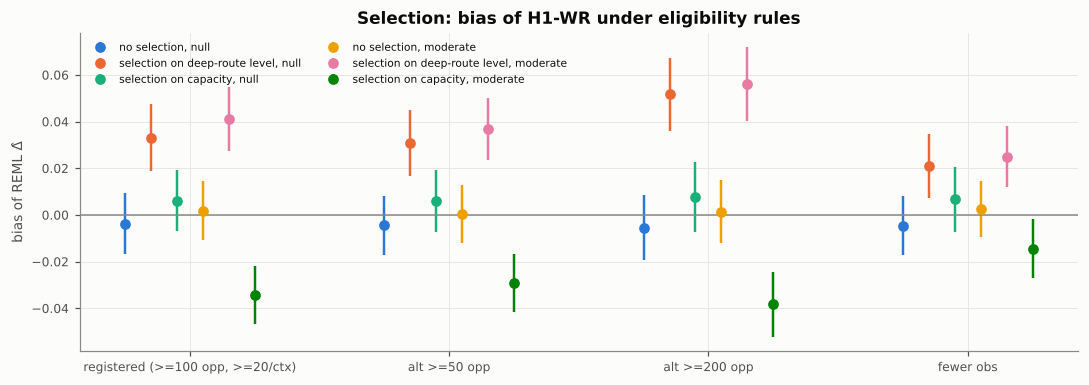

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.6))
rules = list(ps.SEL_RULES)
for k, mid in enumerate([1, 2, 3, 4, 5, 6]):
    g = SS.filter(pl.col('mech') == mid)
    vals = [g.filter(pl.col('rule') == r)['bias_reml'][0] for r in rules]
    errs = [1.96 * g.filter(pl.col('rule') == r)['bias_reml_mcse'][0] for r in rules]
    ax.errorbar(np.arange(4) + (k - 2.5) * 0.1, vals, yerr=errs, fmt='o', color=style.SERIES[k], label=g['mechanism'][0])
ax.axhline(0, color=style.MUTED, lw=1); ax.set_xticks(range(4), [r.split(':')[0] for r in rules], fontsize=8); ax.set_ylabel('bias of REML Δ̂')
ax.legend(fontsize=7, ncol=2); ax.set_title('Selection: bias of H1-WR under eligibility rules')
fig.tight_layout(); fig.savefig(FIG / 'p4_selection.png', dpi=150); plt.show()

In [19]:
ps.selection_reml_approx(sel, pl.read_parquet(OUT / 'h1_warp.parquet')).sort('mech', 'rule')

mech,mechanism,rule,reps,reject_reml_approx,reject_mcse,coverage_reml_approx
i64,str,str,i64,f64,f64,f64
1,"""no selection, null""","""alt >=200 opp""",300,0.003,0.003,0.990
1,"""no selection, null""","""alt >=50 opp""",300,0.003,0.003,0.993
1,"""no selection, null""","""fewer obs: all pool (>=5/ctx)""",300,0.007,0.005,0.990
1,"""no selection, null""","""registered (>=100 opp, >=20/ctx)""",300,0.003,0.003,0.993
2,"""selection on deep-route level, null""","""alt >=200 opp""",300,0.040,0.011,0.957
2,"""selection on deep-route level, null""","""alt >=50 opp""",300,0.023,0.009,0.977
2,"""selection on deep-route level, null""","""fewer obs: all pool (>=5/ctx)""",300,0.017,0.007,0.983
2,"""selection on deep-route level, null""","""registered (>=100 opp, >=20/ctx)""",300,0.037,0.011,0.963
3,"""selection on capacity, null""","""alt >=200 opp""",300,0.020,0.008,0.970


**Estimand shift vs estimator bias.** Δ_eff is the expected Δ among the players a rule retains, from the same latent generator with no outcome noise. Estimator bias is measured against Δ_eff. The remainder (Δ_eff − nominal) is a change of target population, not an error.

In [20]:
tgt = ps.selection_effective_truth(4000)
tgt.join(SS.select('mech','rule','mean_delta_reml','mean_delta_moment'), on=['mech','rule']).with_columns(
    (pl.col('delta_eff') - pl.col('nominal_delta_obs')).alias('estimand_shift'),
    (pl.col('mean_delta_reml') - pl.col('delta_eff')).alias('reml_bias_vs_target'),
    (pl.col('mean_delta_moment') - pl.col('delta_eff')).alias('moment_bias_vs_target')).sort('mech','rule')

mech,mechanism,rule,n_players,nominal_delta_obs,delta_eff,mean_delta_reml,mean_delta_moment,estimand_shift,reml_bias_vs_target,moment_bias_vs_target
i64,str,str,i64,f64,f64,f64,f64,f64,f64,f64
1,"""no selection, null""","""alt >=200 opp""",45,0.000,-0.001,-0.005,0.002,-0.001,-0.004,0.004
1,"""no selection, null""","""alt >=50 opp""",61,0.000,-0.000,-0.004,0.004,-0.000,-0.004,0.004
1,"""no selection, null""","""fewer obs: all pool (>=5/ctx)""",69,0.000,-0.001,-0.005,0.002,-0.001,-0.004,0.003
1,"""no selection, null""","""registered (>=100 opp, >=20/ctx)""",57,0.000,-0.000,-0.004,0.003,-0.000,-0.003,0.003
2,"""selection on deep-route level, null""","""alt >=200 opp""",45,0.000,0.028,0.052,0.061,0.028,0.024,0.033
2,"""selection on deep-route level, null""","""alt >=50 opp""",61,0.000,0.005,0.031,0.041,0.005,0.026,0.037
2,"""selection on deep-route level, null""","""fewer obs: all pool (>=5/ctx)""",69,0.000,-0.010,0.021,0.028,-0.010,0.031,0.038
2,"""selection on deep-route level, null""","""registered (>=100 opp, >=20/ctx)""",57,0.000,0.013,0.033,0.041,0.013,0.020,0.028
3,"""selection on capacity, null""","""alt >=200 opp""",45,0.000,0.000,0.008,-0.056,0.000,0.007,-0.056


In [21]:
pl.read_parquet(OUT / 'selection_real.parquet')

pos,rule,players,plays,median_plays_hi,median_plays_lo,mean_high_demand_share,sd_high_demand_share,mean_nfl_year,mean_team_seasons,share_round1_2,share_udfa
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""WR""","""registered (>=100 opp, >=20/ctx)""",57,19960,141.000,144.000,0.514,0.098,1.536,2.070,0.263,0.123
"""WR""","""alt >=50 opp""",61,20162,125.000,115.000,0.518,0.096,1.501,2.000,0.246,0.115
"""WR""","""alt >=200 opp""",45,18602,165.000,189.000,0.501,0.096,1.561,2.200,0.333,0.089
"""WR""","""fewer obs: all pool (>=5/ctx)""",69,20414,106.000,100.000,0.523,0.107,1.467,1.899,0.217,0.101
"""DB""","""registered (>=100 opp, >=20/ctx)""",52,16643,118.000,114.500,0.504,0.179,1.563,2.154,0.288,0.038
"""DB""","""alt >=50 opp""",52,16643,118.000,114.500,0.504,0.179,1.563,2.154,0.288,0.038
"""DB""","""alt >=200 opp""",47,16191,128.000,115.000,0.502,0.180,1.569,2.191,0.277,0.043
"""DB""","""fewer obs: all pool (>=5/ctx)""",67,17298,91.000,77.000,0.482,0.188,1.474,1.970,0.224,0.060


## 5. Demand definition (real game speeds only; no combine data)

In [22]:
cells = pl.read_parquet(OUT / 'demand_cells.parquet')
cells.filter(pl.col('min_plays') == 1).pivot(index=['pos','ctx'], on='def', values='D').sort('pos','ctx')

pos,ctx,share_85,share_90,share_95,share_abs
str,str,f64,f64,f64,f64
"""DB""","""deep_zone""",0.057,0.028,0.013,0.151
"""DB""","""man""",0.125,0.058,0.023,0.280
"""DB""","""under_zone""",0.033,0.014,0.006,0.089
"""DL""","""pass_rush""",0.051,0.026,0.016,0.013
"""DL""","""run""",0.027,0.013,0.006,0.003
"""OL""","""pass_block""",0.013,0.008,0.004,0.000
"""OL""","""run""",0.017,0.009,0.004,0.000
"""TE""","""deep""",0.440,0.184,0.071,0.354
"""TE""","""short""",0.058,0.023,0.009,0.040


In [23]:
pl.read_parquet(OUT / 'demand_threshold_agreement.parquet').sort('pos','ctx')

pos,ctx,n,rho_85_90,rho_90_95,rho_85_95,rho_90_abs
str,str,i64,f64,f64,f64,f64
"""DB""","""deep_zone""",52,0.839,0.653,0.543,0.319
"""DB""","""man""",53,0.883,0.805,0.720,0.586
"""DB""","""under_zone""",54,0.825,0.802,0.605,0.751
"""DL""","""pass_rush""",53,0.931,0.813,0.822,-0.145
"""DL""","""run""",53,0.781,0.754,0.644,0.210
"""OL""","""pass_block""",53,0.885,0.836,0.704,-0.288
"""OL""","""run""",53,0.916,0.813,0.826,-0.137
"""TE""","""deep""",17,0.956,0.904,0.860,0.569
"""TE""","""short""",18,0.684,0.586,0.468,0.239


In [24]:
from scipy.stats import spearmanr
wide = cells.filter(pl.col('min_plays') == 1).pivot(index=['pos','ctx'], on='def', values='D')
pl.DataFrame([dict(pair=f'{a} vs {b}', spearman_over_11_cells=spearmanr(wide[a], wide[b]).statistic)
              for a, b in [('share_85','share_90'), ('share_90','share_95'), ('share_85','share_95'), ('share_90','share_abs')]])

pair,spearman_over_11_cells
str,f64
"""share_85 vs share_90""",0.945
"""share_90 vs share_95""",0.982
"""share_85 vs share_95""",0.927
"""share_90 vs share_abs""",0.761


In [25]:
rel = pl.read_parquet(OUT / 'demand_reliability.parquet')
rel.pivot(index=['pos','ctx','n'], on='threshold', values='spearman_brown').sort('pos','ctx')

pos,ctx,n,85,90,95
str,str,i64,f64,f64,f64
"""DB""","""deep_zone""",52,0.479,0.179,0.084
"""DB""","""man""",50,0.709,0.712,0.227
"""DB""","""under_zone""",52,0.546,0.460,0.088
"""DL""","""pass_rush""",53,0.749,0.659,0.567
"""DL""","""run""",53,0.564,-0.010,-0.010
"""OL""","""pass_block""",53,0.684,0.595,0.272
"""OL""","""run""",53,0.687,0.686,0.458
"""TE""","""deep""",15,0.909,0.931,0.315
"""TE""","""short""",18,0.532,-0.300,-1.743


In [26]:
xf = pl.read_parquet(OUT / 'demand_crossfit.parquet')
reg = xf.filter(pl.col('split') == -1)
inst = xf.filter(pl.col('split') >= 0).group_by('pos','ctx').agg(pl.col('D_full').first(), pl.col('D_half').mean().alias('mean_half'),
        pl.col('D_half').std().alias('sd_half'), (pl.col('D_half') - pl.col('D_full')).mean().alias('bias_half'),
        pl.col('D_half').quantile(0.05).alias('q05'), pl.col('D_half').quantile(0.95).alias('q95')).sort('pos','ctx')
display(reg.sort('pos','ctx','half')); inst

ctx,D_full,players,D_half,players_right,pos,half,split
str,f64,u32,f64,u32,str,str,i32
"""deep_zone""",0.028,56,0.028,28,"""DB""","""A""",-1
"""deep_zone""",0.028,56,0.028,28,"""DB""","""B""",-1
"""man""",0.058,56,0.069,28,"""DB""","""A""",-1
"""man""",0.058,56,0.050,28,"""DB""","""B""",-1
"""under_zone""",0.014,56,0.014,28,"""DB""","""A""",-1
"""under_zone""",0.014,56,0.014,28,"""DB""","""B""",-1
"""pass_rush""",0.026,53,0.025,26,"""DL""","""A""",-1
"""pass_rush""",0.026,53,0.030,27,"""DL""","""B""",-1
"""run""",0.013,53,0.013,26,"""DL""","""A""",-1


pos,ctx,D_full,mean_half,sd_half,bias_half,q05,q95
str,str,f64,f64,f64,f64,f64,f64
"""DB""","""deep_zone""",0.028,0.029,0.002,0.001,0.026,0.032
"""DB""","""man""",0.058,0.060,0.009,0.002,0.049,0.074
"""DB""","""under_zone""",0.014,0.013,0.003,-0.000,0.010,0.018
"""DL""","""pass_rush""",0.026,0.028,0.004,0.002,0.023,0.037
"""DL""","""run""",0.013,0.013,0.001,0.000,0.011,0.014
"""OL""","""pass_block""",0.008,0.008,0.001,-0.000,0.006,0.009
"""OL""","""run""",0.009,0.009,0.001,0.000,0.008,0.011
"""TE""","""deep""",0.184,0.179,0.048,-0.005,0.098,0.244
"""TE""","""short""",0.023,0.024,0.004,0.001,0.020,0.034


In [27]:
oos = pl.read_parquet(OUT / 'demand_oos_T.parquet')
oos.group_by('pos','ctx','T_source').agg(pl.col('D').mean()).pivot(index=['pos','ctx'], on='T_source', values='D').sort('pos','ctx')

pos,ctx,out_of_sample_T,in_sample_T
str,str,f64,f64
"""DB""","""deep_zone""",0.038,0.040
"""DB""","""man""",0.083,0.092
"""DB""","""under_zone""",0.016,0.017
"""DL""","""pass_rush""",0.040,0.043
"""DL""","""run""",0.017,0.021
"""OL""","""pass_block""",0.011,0.013
"""OL""","""run""",0.015,0.015
"""TE""","""deep""",0.272,0.307
"""TE""","""short""",0.028,0.037


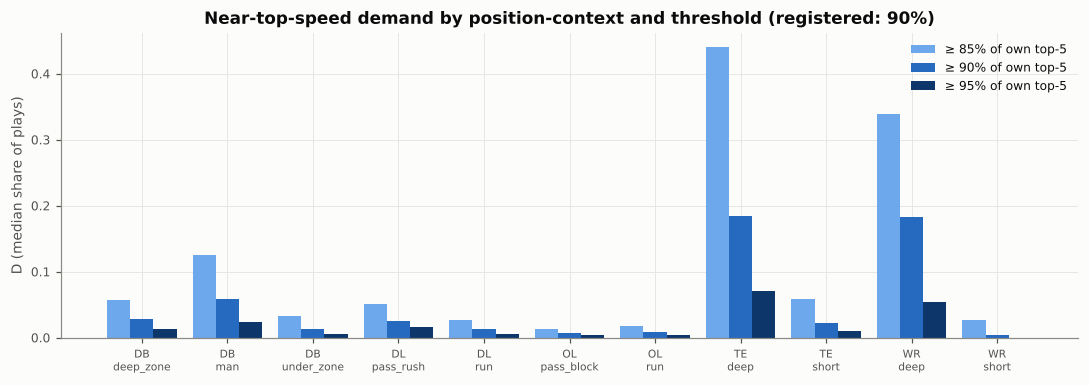

In [28]:
fig, ax = plt.subplots(figsize=(10, 3.6))
cc = cells.filter(pl.col('min_plays') == 1).sort('pos','ctx')
keys = cc.select('pos','ctx').unique(maintain_order=True)
for k, d in enumerate(['share_85','share_90','share_95']):
    v = [cc.filter((pl.col('pos')==p)&(pl.col('ctx')==c)&(pl.col('def')==d))['D'][0] for p, c in keys.iter_rows()]
    ax.bar(np.arange(keys.height) + (k-1)*0.27, v, width=0.27, color=style.SEQ_BLUE[2+2*k], label=d.replace('share_','≥ ')+'% of own top-5')
ax.set_xticks(range(keys.height), [f'{p}\n{c}' for p, c in keys.iter_rows()], fontsize=7); ax.set_ylabel('D (median share of plays)'); ax.legend()
ax.set_title('Near-top-speed demand by position-context and threshold (registered: 90%)')
fig.tight_layout(); fig.savefig(FIG / 'p4_demand_thresholds.png', dpi=150); plt.show()

In [29]:
ds = pl.read_parquet(OUT / 'demand_sim.parquet')
ds.group_by('lam','crossfit').agg(pl.len().alias('reps'), pl.col('lam_hat').mean(), pl.col('lam_hat').std().alias('sd'), pl.col('reject').mean()).sort('lam','crossfit')

lam,crossfit,reps,lam_hat,sd,reject
f64,bool,u32,f64,f64,f64
0.000,false,400,0.004,1.110,0.025
0.000,true,400,-0.058,0.979,0.000
1.500,false,400,1.838,1.022,0.395
1.500,true,400,1.938,1.036,0.207
3.000,false,400,3.871,0.962,0.927
3.000,true,400,3.989,0.987,0.902


## 6. Conclusions

See `research_notes/synthetic_validation.md`, `demand_measure_validation.md` and `selection_bias_analysis.md`. Those notes take their numbers from the tables above.